# Data preparation and dataset analysis

Builds the training set and the phased test stream used in every other notebook, and
produces the dataset figures: Fig. 3 (feature distributions), Fig. 9 (pairwise
separability) and Fig. 10 (correlation matrix), together with the Fisher Discriminant
Ratio and the overlap check of Appendix A.

In [2]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from utils import (FEATURES, CLASSES, CLASS_NAMES, load_dataset, make_training_set,
                   make_oracle_extra, make_phased_stream, fisher_discriminant_ratio)

DATA_DIR = "data"
FIG_DIR = "figures"
SEED = 42

os.makedirs(FIG_DIR, exist_ok=True)

## Training set and test stream

In [3]:
train_df, test_df = load_dataset(DATA_DIR)
print(f"training file: {len(train_df):,} rows, test file: {len(test_df):,} rows")

X_train, y_train = make_training_set(train_df, seed=SEED)
X_extra, y_extra = make_oracle_extra(train_df, seed=SEED)
X_stream, y_stream, phase_starts = make_phased_stream(test_df, seed=SEED)

counts = pd.DataFrame({
    "training set": np.bincount(y_train, minlength=4),
    "oracle extra": np.bincount(y_extra, minlength=4),
    "test stream": np.bincount(y_stream, minlength=4),
}, index=CLASS_NAMES)
counts.loc["total"] = counts.sum()
counts

training file: 2,721,600 rows, test file: 907,200 rows


,training set,oracle extra,test stream
Normal,10000,0,8399
ECL,10000,0,6641
EDFA,0,1994,5805
NLI,0,2006,4155
total,20000,4000,25000


In [4]:
for k, start in enumerate(phase_starts):
    phase = y_stream[start:start + 5000]
    present = {CLASS_NAMES[c]: int((phase == c).sum()) for c in CLASSES if (phase == c).any()}
    print(f"phase {k + 1} (from sample {start}): {present}")

phase 1 (from sample 0): {'Normal': 2530, 'ECL': 2470}
phase 2 (from sample 5000): {'Normal': 1711, 'ECL': 1683, 'EDFA': 1606}
phase 3 (from sample 10000): {'Normal': 1242, 'ECL': 1263, 'EDFA': 1281, 'NLI': 1214}
phase 4 (from sample 15000): {'Normal': 1673, 'EDFA': 1660, 'NLI': 1667}
phase 5 (from sample 20000): {'Normal': 1243, 'ECL': 1225, 'EDFA': 1258, 'NLI': 1274}


## Overlap between the training data and the stream

All samples are compared on their four feature values. The training set and the oracle's
extra samples come from the training file and the stream from the test file, so no
sample should appear in both.

In [5]:
def as_rows(X):
    return set(map(tuple, X[FEATURES].round(8).to_numpy()))


stream_rows = as_rows(X_stream)
print("training set samples also in the stream:", len(as_rows(X_train) & stream_rows))
print("oracle extra samples also in the stream:", len(as_rows(X_extra) & stream_rows))
print("duplicate samples inside the stream:   ", len(X_stream) - len(stream_rows))

training set samples also in the stream: 0
oracle extra samples also in the stream: 0
duplicate samples inside the stream:    0


## Fig. 3: feature distributions per failure type

Computed on the whole training file. BER is stored in the dataset as 10·log10(BER), so it
is divided by 10 to plot log10(BER).

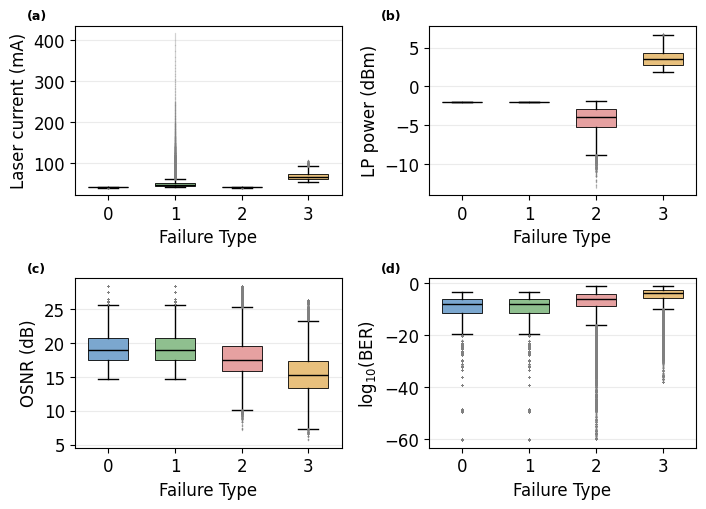

In [5]:
panels = [("Laser current (mA)", "Laser current (mA)"),
          ("LP power (dBm)", "LP power (dBm)"),
          ("OSNR (dB)", "OSNR (dB)"),
          ("BER (dB)", "log$_{10}$(BER)")]
box_colors = ["#7ba7cf", "#8fbf8f", "#e6a1a1", "#e8c07d"]

fig, axes = plt.subplots(2, 2, figsize=(7.16, 5.2))
for ax, (column, ylabel), letter in zip(axes.ravel(), panels, "abcd"):
    data = []
    for c in CLASSES:
        values = train_df.loc[train_df["Failure type"] == c, column].to_numpy(dtype=float)
        if column == "BER (dB)":
            values = values / 10
        data.append(values)

    boxes = ax.boxplot(data, patch_artist=True, widths=0.6,
                       medianprops=dict(color="black", lw=1),
                       flierprops=dict(marker=".", markersize=2, alpha=0.3,
                                       markerfacecolor="gray", markeredgecolor="none"))
    for patch, color in zip(boxes["boxes"], box_colors):
        patch.set_facecolor(color)
        patch.set_edgecolor("black")
        patch.set_linewidth(0.6)

    ax.set_xticks(range(1, 5), ["0", "1", "2", "3"])
    ax.set_xlabel("Failure Type", fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    ax.tick_params(labelsize=12)
    ax.grid(alpha=0.25, axis="y")
    ax.text(-0.18, 1.02, f"({letter})", transform=ax.transAxes, fontsize=9,
            fontweight="bold", va="bottom")

fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig3_feature_distributions.pdf", bbox_inches="tight")
plt.show()

## Fisher Discriminant Ratio (Appendix A)

Computed on the test stream, per feature and averaged over the four features.

In [7]:
X_test, y_test = test_df[FEATURES], test_df["Failure type"].to_numpy()
ratios, mean_fdr = fisher_discriminant_ratio(X_test, y_test)
for feature, value in ratios.items():
    print(f"{feature:20s} {value:8.2f}")
print(f"{'mean':20s} {mean_fdr:8.2f}")

Laser current (mA)      39.90
LP power (dBm)          94.08
OSNR (dB)                0.10
BER (dB)                 0.04
mean                    33.53


## Fig. 9: pairwise feature separability

2000 samples drawn at random from the test stream.

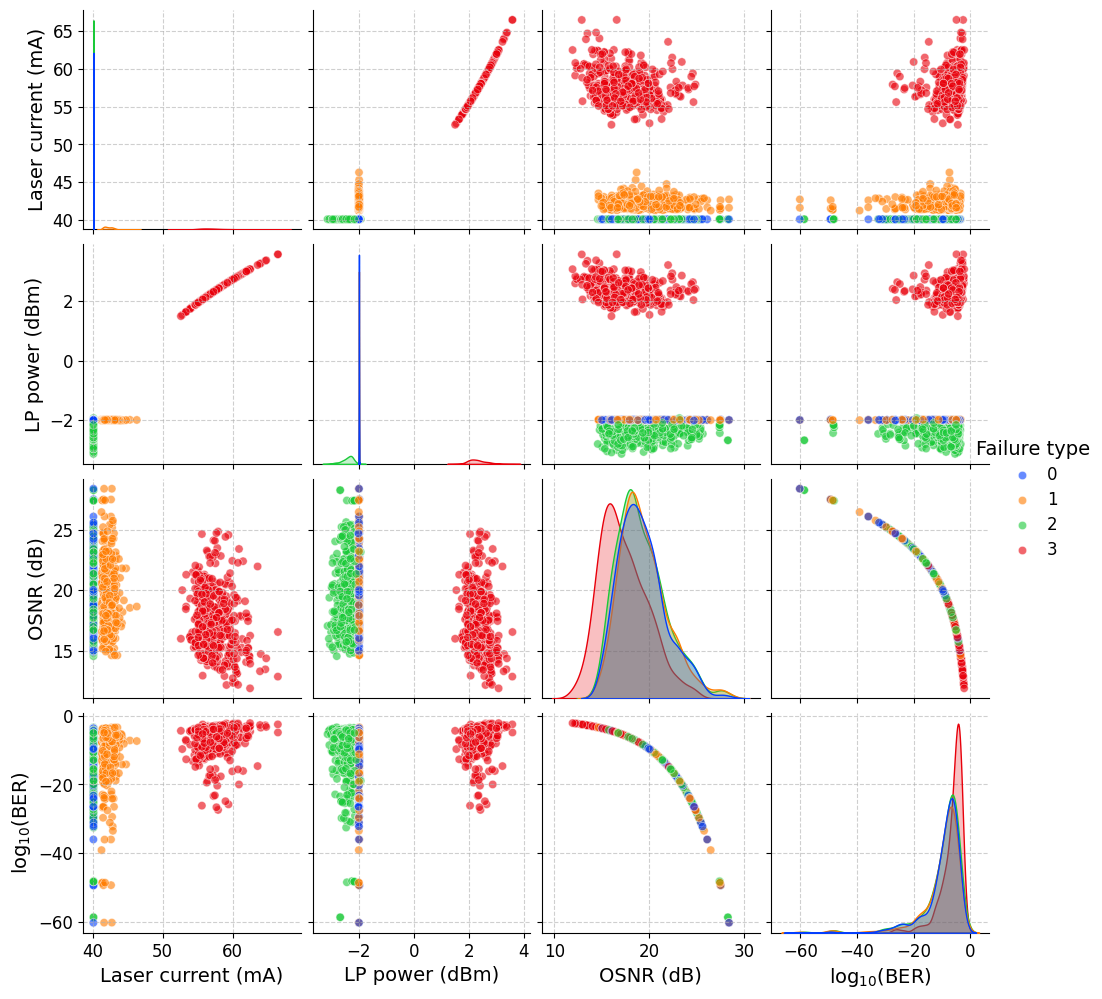

In [9]:
plot_df = X_test.copy()
plot_df["log10(BER)"] = plot_df["BER (dB)"] / 10
plot_df["Failure type"] = y_test
plot_df = plot_df.sample(2000, random_state=SEED)

grid = sns.pairplot(plot_df, hue="Failure type", palette="bright", plot_kws={"alpha": 0.6},
                    vars=["Laser current (mA)", "LP power (dBm)", "OSNR (dB)", "log10(BER)"])
for ax in grid.axes.flatten():
    ax.xaxis.label.set_size(14)
    ax.yaxis.label.set_size(14)
    ax.tick_params(axis="both", labelsize=12)
    ax.grid(True, linestyle="--", alpha=0.6)
    if ax.get_xlabel() == "log10(BER)":
        ax.set_xlabel("log$_{10}$(BER)")
    if ax.get_ylabel() == "log10(BER)":
        ax.set_ylabel("log$_{10}$(BER)")
plt.setp(grid.legend.get_title(), fontsize=14)
plt.setp(grid.legend.get_texts(), fontsize=12)
grid.savefig(f"{FIG_DIR}/fig9_pairwise_separability.pdf", bbox_inches="tight")
plt.show()

## Fig. 10: correlation matrix

Computed on the test stream. Dividing BER by 10 does not change any correlation.

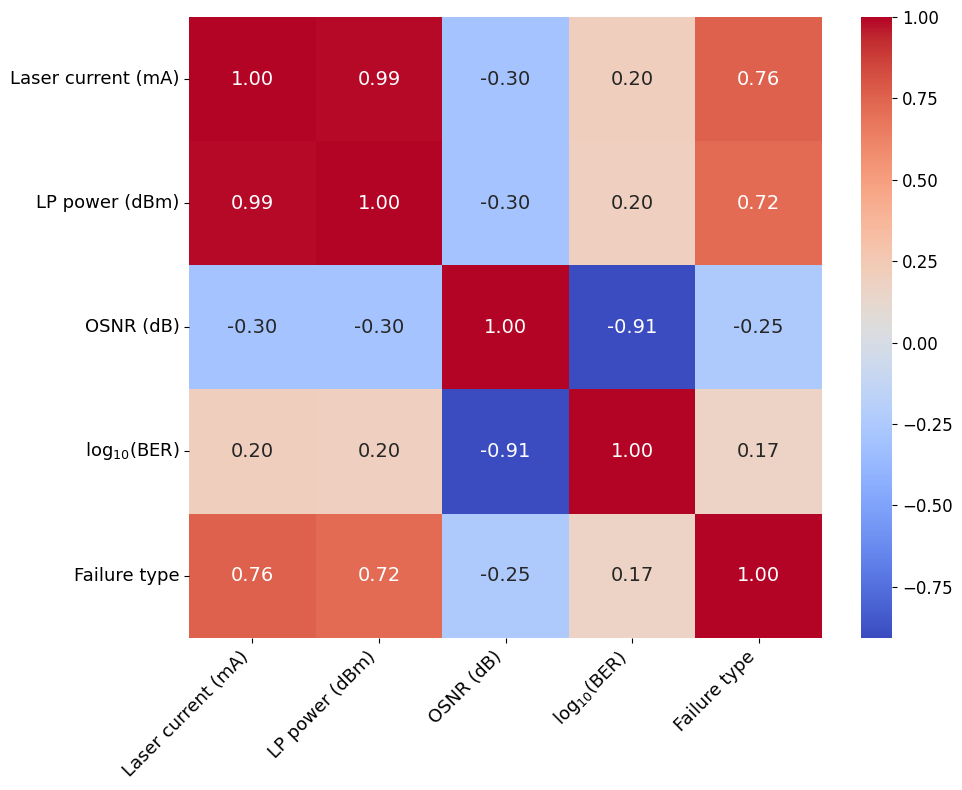

Laser current (mA)    0.76
LP power (dBm)        0.72
OSNR (dB)            -0.25
log$_{10}$(BER)       0.17
Name: Failure type, dtype: float64


In [10]:
corr_df = X_test.copy()
corr_df["log$_{10}$(BER)"] = corr_df.pop("BER (dB)") / 10
corr_df["Failure type"] = y_test
corr = corr_df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", annot_kws={"size": 14}, ax=ax)
ax.tick_params(axis="x", labelsize=13, rotation=45)
ax.tick_params(axis="y", labelsize=13, rotation=0)
plt.setp(ax.get_xticklabels(), ha="right")
ax.collections[0].colorbar.ax.tick_params(labelsize=12)
fig.tight_layout()
fig.savefig(f"{FIG_DIR}/fig10_correlation_matrix.pdf", bbox_inches="tight")
plt.show()

print(corr["Failure type"].drop("Failure type").round(2))